# Validazione esterna: complessità dei prodotti vs misure indipendenti

Confronta le misure di complessità dei prodotti (estese e classiche) con misure costruite **senza** dati di commercio
(notebook `data_generation/misure_esterne_prodotti.ipynb`):
classe tecnologica di Lall, prodotti ad alta tecnologia (ATP, US Census), intensità di R&D del settore (OECD),
valore aggiunto per addetto, quota di lavoratori qualificati, salario, capitale per addetto (NBER-CES).

Le misure settoriali sono le stesse per tutti i prodotti di un'industria: oltre alle correlazioni sui prodotti,
si riportano le correlazioni a livello di industria NAICS (mediana della complessità dei prodotti dell'industria).
Tutte le correlazioni sono di rango (Spearman). Figure in `plots/econometria/confronto_misure_esterne/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = next(p for p in [Path().resolve(), *Path().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.storage import load_metrics_long, load_external_product
import matplotlib.pyplot as plt
from src.plotting import (set_style, figsize, save_fig, two_part_legend, common_ylim,
                          SINGLE, HALF, PALETTE, RES_MARKER, SEQ_CMAP, SYMBOLS)

set_style()

METRIC_COLOR = {"extended_fitness": "#0072B2", "fitness": "#56B4E9", "extended_eci": "#D55E00", "eci": "#E69F00", "N1": "#000000"}

## Configurazione

In [2]:
YEAR = 2002
RES = 6                                   # 6 = HS6 (piu' fine), 4 = HS4
METRICS = {                                # colonna -> ((metrica, variabile) nei file, etichetta)
    "extended_fitness": (("extended_fitness", "Q"), "Extended Fitness"),
    "extended_eci":     (("extended_eci", "Q"),     "Extended ECI"),
    "fitness":     (("fitness", "Q"),     "Fitness"),
    "eci":         (("eci", "PCI"),       "ECI (PCI)"),
}
EXTERNAL = {                               # colonna -> etichetta
    "lall_classe": "classe Lall", "quota_atp": "quota ATP", "rd_intensity": "R&D / VA",
    "va_per_addetto": "VA per addetto", "quota_skill": "quota skill",
    "salario_medio": "salario medio", "capitale_per_addetto": "capitale per addetto",
}
MIN_PRODOTTI_INDUSTRIA = 3                 # industrie con meno prodotti escluse dal confronto per industria
LALL_NAME = {0: "primari", 1: "basati su risorse", 2: "bassa tecn.", 3: "media tecn.", 4: "alta tecn."}

SAVE_FIGS = True
FIG_DIR = ROOT / "plots" / "econometria" / "confronto_misure_esterne" 

## Dati

In [3]:
r = load_metrics_long(RES, "product", years=[YEAR]).pivot_table(index="product", columns=["metric", "variable"], values="value")
D = pd.DataFrame({k: r[mv] for k, (mv, _) in METRICS.items()})
C = pd.read_parquet(ROOT / "data" / "HS02_all_years" / f"{RES}_digits" / "alligned" / "binarized" / "C" / f"C_{RES}_digits_HS02.parquet")
D["N1"] = C.sum(axis=0).reindex(D.index)
ext = load_external_product(RES)
D = D.join(ext, how="left")
LABELS = {**{k: v[1] for k, v in METRICS.items()}, "N1": r"$N_1$"}
print(f"{len(D)} prodotti; con classe Lall: {D.lall_classe.notna().sum()}, con dati NBER: {D.va_per_addetto.notna().sum()}")

5079 prodotti; con classe Lall: 5046, con dati NBER: 4573


## 1. Correlazioni di rango con le misure esterne

Tabelle per prodotto e per industria NAICS. Le due danno lo stesso quadro (le misure esterne sono settoriali),
quindi la figura riassuntiva (sezione 3) usa solo quella per prodotto.

In [4]:
def spearman_table(df, rows, cols):
    return pd.DataFrame({c: [df[[r_, c]].dropna().corr(method="spearman").iloc[0, 1] for r_ in rows] for c in cols},
                        index=rows)

rows = list(METRICS) + ["N1"]
prod = spearman_table(D, rows, list(EXTERNAL))

# a livello di industria NAICS: mediana della complessita' dei prodotti dell'industria
ind = D.dropna(subset=["naics"]).groupby("naics")
n_per_ind = ind.size()
I = ind[rows].median().join(ind[list(EXTERNAL)].first())[n_per_ind >= MIN_PRODOTTI_INDUSTRIA]
ind_tab = spearman_table(I, rows, [c for c in EXTERNAL if c not in ("lall_classe", "quota_atp")])
print(f"industrie NAICS con almeno {MIN_PRODOTTI_INDUSTRIA} prodotti: {len(I)}")

def heatmap(T, title_file, row_labels, separators=(), col_labels=None, cmap="RdBu_r", vmin=-1, vmax=1,
            cbar_label=r"$\rho_S$", rotation=35, col_separators=()):
    fig, ax = plt.subplots(figsize=(figsize(0.85)[0], 0.27 * T.shape[0] + 1.1))
    im = ax.imshow(T.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(T.shape[1])); ax.set_xticklabels(col_labels or [EXTERNAL[c] for c in T.columns], rotation=rotation,
                       ha="right" if rotation else "center")
    ax.set_yticks(range(T.shape[0])); ax.set_yticklabels(row_labels)
    ax.tick_params(which="both", length=0)
    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            v = T.values[i, j]
            ax.text(j, i, f"{v:.2f}".replace("-0.00", "0.00"), ha="center", va="center", fontsize=7, color="white" if abs(v - (vmin + vmax) / 2) > 0.3 * (vmax - vmin) else "k")
    for r_ in separators:
        ax.axhline(r_ - 0.5, color="white", lw=2.5)
    for c_ in col_separators:
        ax.axvline(c_ - 0.5, color="white", lw=2.5)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03); cb.set_label(cbar_label)
    fig.tight_layout()
    if SAVE_FIGS:
        save_fig(fig, FIG_DIR / title_file)
    plt.show()

print("per prodotto"); display(prod.round(2))
print("per industria NAICS"); display(ind_tab.round(2))

industrie NAICS con almeno 3 prodotti: 329
per prodotto


,lall_classe,quota_atp,rd_intensity,va_per_addetto,quota_skill,salario_medio,capitale_per_addetto
extended_fitness,0.46,0.09,0.33,-0.09,0.11,0.05,-0.11
extended_eci,0.45,0.05,0.08,-0.42,-0.18,-0.34,-0.46
fitness,0.15,0.05,0.29,0.20,0.15,0.29,0.26
eci,0.28,0.17,0.49,0.41,0.38,0.58,0.30
N1,0.45,0.04,0.08,-0.38,-0.19,-0.33,-0.43


per industria NAICS


,rd_intensity,va_per_addetto,quota_skill,salario_medio,capitale_per_addetto
extended_fitness,0.44,-0.22,0.17,0.05,-0.27
extended_eci,0.28,-0.36,0.02,-0.16,-0.44
fitness,0.34,0.14,0.13,0.33,0.25
eci,0.56,0.31,0.40,0.62,0.24
N1,0.28,-0.34,0.01,-0.17,-0.43


## 2. Complessità per classe tecnologica di Lall

Per rendere confrontabili le metriche si usa il percentile di rango di ogni prodotto (0 = meno complesso, 1 = più complesso).

- **(a)** le 5 macro-classi di Lall: punto = media della classe, barra = intervallo di confidenza al 95%;
- **(b)** le 10 sottoclassi di Lall (2000): percentile medio in ogni cella, con $N_1$ (numero di input) come controllo.
  Le linee bianche separano le macro-classi; fra parentesi il numero di prodotti.

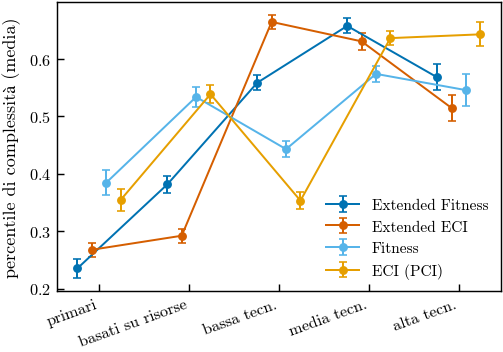

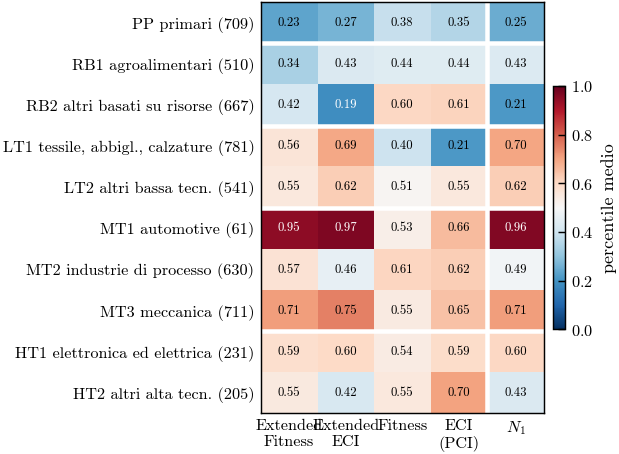

In [5]:
# (a) macro-classi
fig, ax = plt.subplots(figsize=figsize(*SINGLE))
classes = sorted(D["lall_classe"].dropna().unique())
offsets = np.linspace(-0.24, 0.24, len(METRICS))
for off, k in zip(offsets, METRICS):
    pr = D[k].rank(pct=True)
    g = pr.groupby(D["lall_classe"])
    m, se = g.mean(), g.std() / np.sqrt(g.size())
    ax.errorbar(np.array(classes) + off, m.reindex(classes), yerr=1.96 * se.reindex(classes), fmt="o-",
                color=METRIC_COLOR[k], capsize=2, ms=4, lw=1.1, label=METRICS[k][1])
ax.set_xticks(classes); ax.set_xticklabels([LALL_NAME[int(c)] for c in classes], rotation=20, ha="right")
ax.set_ylabel("percentile di complessità (media)")
ax.legend(loc="lower right")
fig.tight_layout()
if SAVE_FIGS:
    save_fig(fig, FIG_DIR / f"percentile_per_classe_lall_hs{RES}_{YEAR}")
plt.show()

# (b) sottoclassi (LDC99 = non classificati, esclusi)
LALL_SUB = {"LDC01": "PP primari", "LDC02": "RB1 agroalimentari", "LDC03": "RB2 altri basati su risorse",
            "LDC04": "LT1 tessile, abbigl., calzature", "LDC05": "LT2 altri bassa tecn.",
            "LDC06": "MT1 automotive", "LDC07": "MT2 industrie di processo", "LDC08": "MT3 meccanica",
            "LDC09": "HT1 elettronica ed elettrica", "LDC10": "HT2 altri alta tecn."}
SHOW = list(METRICS) + ["N1"]
codes = list(LALL_SUB)
n_per_code = D["lall"].value_counts()
sub = pd.DataFrame({k: D[k].rank(pct=True).groupby(D["lall"]).mean() for k in SHOW}).reindex(codes)
heatmap(sub, f"percentile_per_sottoclasse_lall_hs{RES}_{YEAR}",
        [f"{LALL_SUB[c]} ({n_per_code.get(c, 0)})" for c in codes],
        separators=(1, 3, 5, 8),                    # confini fra le macro-classi
        col_labels=[METRICS[k][1].replace(" ", "\n", 1) if k in METRICS else LABELS[k] for k in SHOW],
        col_separators=[len(METRICS)],
        vmin=0, vmax=1, cbar_label="percentile medio", rotation=0)

## 3. Correlazioni con le misure esterne

Due figure:

1. correlazione di Spearman delle metriche così come sono, con $N_1$ (numero di input del prodotto) come riferimento;
2. confronto a coppie fra la metrica classica e la parte della metrica estesa che non è "contare gli input":
   correlazione parziale di Spearman tenendo fisso $N_1$,
$$\rho_{XE\cdot N} = \frac{\rho_{XE} - \rho_{XN}\,\rho_{EN}}{\sqrt{(1-\rho_{XN}^2)(1-\rho_{EN}^2)}}.$$
   Per le metriche classiche si usa la correlazione semplice: tenere fisso $N_1$ le cambia al massimo di qualche
   centesimo (verifica nella tabella stampata sotto), mentre per le metriche estese cambia anche il segno.

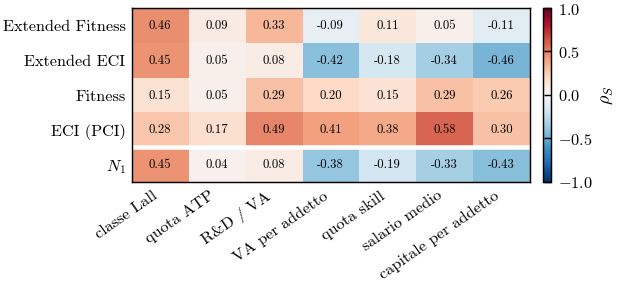

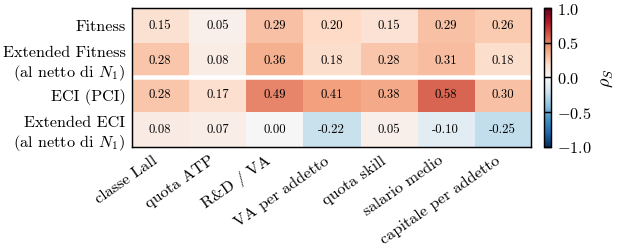

semplice                                        \
                 lall_classe quota_atp rd_intensity va_per_addetto   
extended_fitness        0.46      0.09         0.33          -0.09   
extended_eci            0.45      0.05         0.08          -0.42   
fitness                 0.15      0.05         0.29           0.20   
eci                     0.28      0.17         0.49           0.41   

                                                                 \
                 quota_skill salario_medio capitale_per_addetto   
extended_fitness        0.11          0.05                -0.11   
extended_eci           -0.18         -0.34                -0.46   
fitness                 0.15          0.29                 0.26   
eci                     0.38          0.58                 0.30   

                 al netto di N1                         ...              \
                    lall_classe quota_atp rd_intensity  ... quota_skill   
extended_fitness           0.28      0.08         0.36  ...        0.28   
extended_eci               0.08      0.07        -0.00  ...        0.05   
fitness                    0.23      0.05         0.30  ...        0.11   
eci                        0.34      0.17         0.50  ...        0.37   

                                                     differenza            \
                 salario_medio capitale_per_addetto lall_classe quota_atp   
extended_fitness          0.31                 0.18       -0.19     -0.01   
extended_eci             -0.10                -0.25       -0.37      0.02   
fitness                   0.25                 0.20        0.08      0.00   
eci                       0.58                 0.27        0.06      0.00   

                                                                        \
                 rd_intensity va_per_addetto quota_skill salario_medio   
extended_fitness         0.02           0.26        0.17          0.26   
extended_eci            -0.08           0.20        0.23          0.24   
fitness                  0.01          -0.06       -0.03         -0.05   
eci                      0.01          -0.02       -0.01         -0.01   

                                       
                 capitale_per_addetto  
extended_fitness                 0.29  
extended_eci                     0.22  
fitness                         -0.06  
eci                             -0.03  

[4 rows x 21 columns]

In [6]:
def partial_spearman(df, x, e, z="N1"):
    d = df[[x, e, z]].dropna()
    R = d.corr(method="spearman")
    rxe, rxz, rez = R.loc[x, e], R.loc[x, z], R.loc[e, z]
    return (rxe - rxz * rez) / np.sqrt((1 - rxz ** 2) * (1 - rez ** 2))

part = pd.DataFrame({e: [partial_spearman(D, k, e) for k in METRICS] for e in EXTERNAL}, index=list(METRICS))

# 1. metriche cosi' come sono (+ N1 come riferimento)
rows1 = list(METRICS) + ["N1"]
heatmap(prod.loc[rows1], f"spearman_misure_esterne_hs{RES}_{YEAR}", [LABELS[k] for k in rows1],
        separators=[len(METRICS)])

# 2. classica vs estesa al netto di N1, a coppie
pairs = [("fitness", "extended_fitness"), ("eci", "extended_eci")]
blocks, labels = [], []
for classic, ext_ in pairs:
    blocks += [prod.loc[classic], part.loc[ext_]]
    labels += [LABELS[classic], f"{LABELS[ext_]}\n(al netto di $N_1$)"]
heatmap(pd.DataFrame(blocks).reset_index(drop=True), f"spearman_misure_esterne_netto_N1_hs{RES}_{YEAR}",
        labels, separators=[2])

# verifica: per le metriche classiche tenere fisso N1 cambia poco
pd.concat({"semplice": prod.loc[list(METRICS)], "al netto di N1": part,
           "differenza": part - prod.loc[list(METRICS)]}, axis=1).round(2)

### Lettura

- Le correlazioni semplici della fitness estesa con le misure di produttività (VA, salario, capitale per addetto) sono
  quasi nulle o negative: $N_1$ è correlato **negativamente** con queste misure, e la fitness estesa eredita questo legame.
- Al netto di $N_1$ la fitness estesa diventa positivamente correlata con tutte le misure esterne, e quasi sempre più della fitness classica:
  la parte della fitness estesa che non è "contare gli input" va nella direzione giusta.
- L'ECI esteso al netto di $N_1$ non porta quasi informazione: la sua variabilità è dominata da $N_1$.
- Il PCI classico resta la misura più allineata alle misure esterne di produttività.